In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import scipy.stats as stats
import sympy as sym
import matplotlib.pyplot as plt
import cvxpy as cv

Part A

In [2]:
yahoo = pd.read_csv('time_series_US_20031231-1800_20261011-1650.csv')

N = len(yahoo)
t = np.arange(1, N+1)

y = yahoo['yahoo']
X = np.zeros((N,N))

lmbda = np.logspace(-3,6,91)

for i in range(1,N):
    X[:,i] = np.maximum((t - i),0)
X[:,0] = 1
sym.pprint(X)
yahoo.head()

[[  1.   0.   0. ...   0.   0.   0.] 
 [  1.   1.   0. ...   0.   0.   0.] 
 [  1.   2.   1. ...   0.   0.   0.] 
                 ...                 
 [  1. 271. 270. ...   1.   0.   0.] 
 [  1. 272. 271. ...   2.   1.   0.] 
 [  1. 273. 272. ...   3.   2.   1.]]


,Time,yahoo
0,2004-01-01,39
1,2004-02-01,39
2,2004-03-01,40
3,2004-04-01,41
4,2004-05-01,42


In [3]:
K = 5
idx = np.arange(N)

D = np.ones(N)
D[:2] = 0
D = np.diag(D)

cv_error = []
for lam in lmbda:
    fold_error = []
    for k in range(K):
        test  = (idx % K == k)
        train = ~test
        X_train, y_train = X[train], y[train]
        X_test,  y_test  = X[test],  y[test]

        A = X_train.T @ X_train + lam * D
        b = X_train.T @ y_train
        beta_hat = np.linalg.solve(A, b)

        pred = X_test @ beta_hat
        fold_error.append(np.mean((y_test - pred)**2))

    cv_error.append(np.mean(fold_error))   # one number per λ

best_lam = lmbda[np.argmin(cv_error)]
print(best_lam)

1.2589254117941675


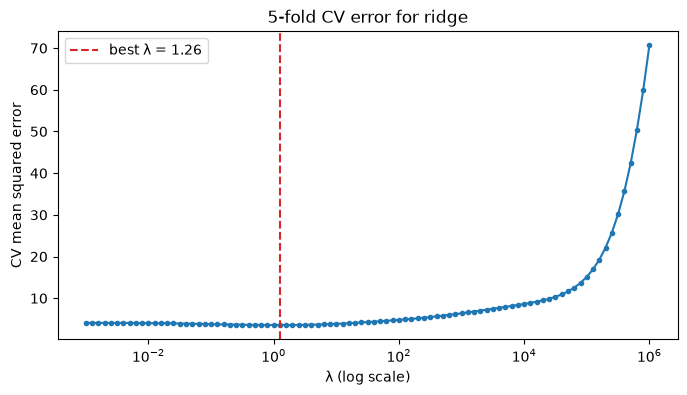

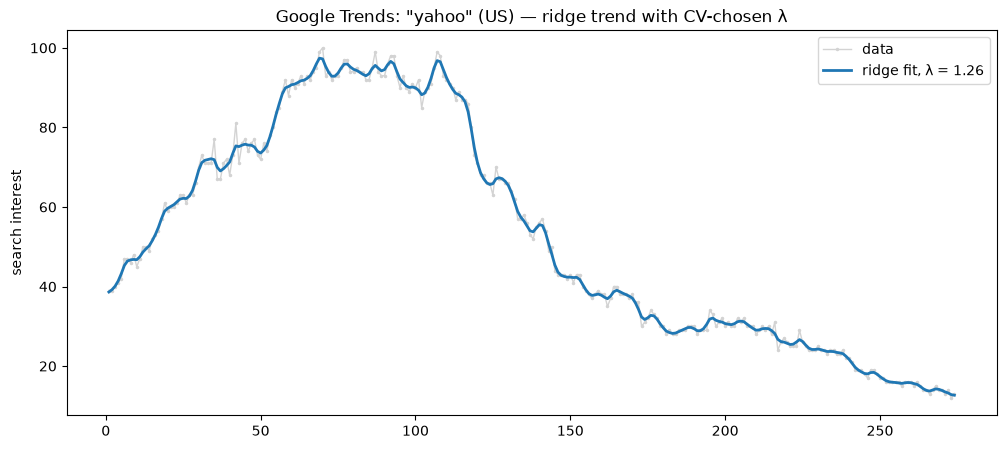

In [4]:

plt.figure(figsize=(8, 4))
plt.semilogx(lmbda, cv_error, marker='o', ms=3)
plt.axvline(best_lam, color='C3', ls='--', label=f'best λ = {best_lam:.3g}')
plt.xlabel('λ (log scale)'); plt.ylabel('CV mean squared error')
plt.title('5-fold CV error for ridge')
plt.legend(); plt.show()

A = X.T @ X + best_lam * D
beta_best = np.linalg.solve(A, X.T @ y)
mu_best = X @ beta_best

plt.figure(figsize=(12, 5))
plt.plot(t, y, color='lightgray', lw=1, marker='.', ms=3, label='data')
plt.plot(t, mu_best, color='C0', lw=2, label=f'ridge fit, λ = {best_lam:.3g}')
plt.ylabel('search interest'); plt.title('Google Trends: "yahoo" (US) — ridge trend with CV-chosen λ')
plt.legend()
plt.show()

The fitted trend function fits the data and is able capture the general trend. However we do see that the trend is not able to capture some of the jumps and peaks.

Part B

i

In [5]:
n = len(y)
XtX = X.T @ X
Xty = X.T @ y
yty = y @ y

def log_post(tau, sigma):
    M = XtX / sigma**2 + D / tau**2
    _, logdetM = np.linalg.slogdet(M)
    quad = Xty @ np.linalg.solve(M, Xty) / sigma**4
    return (-(n - 2) * np.log(tau) - n * np.log(sigma)
            - 0.5 * logdetM - 0.5 * (yty / sigma**2 - quad))

# grid centered on the part (a) estimates
sig0 = np.std(y - mu_best)
tau0 = sig0 / np.sqrt(best_lam)
taus   = tau0 * np.logspace(-2, 2, 60)
sigmas = sig0 * np.logspace(-1, 1, 60)

LP = np.array([[log_post(ta, si) for si in sigmas] for ta in taus])

i, j = np.unravel_index(np.argmax(LP), LP.shape)
tau_hat, sigma_hat = taus[i], sigmas[j]
print(f"tau_hat = {tau_hat:.4g}, sigma_hat = {sigma_hat:.4g}")
print(f"sigma^2/tau^2 = {sigma_hat**2 / tau_hat**2:.4g}   vs   CV lambda = {best_lam:.4g}")



tau_hat = 0.6165, sigma_hat = 1.697
sigma^2/tau^2 = 7.58   vs   CV lambda = 1.259


ii

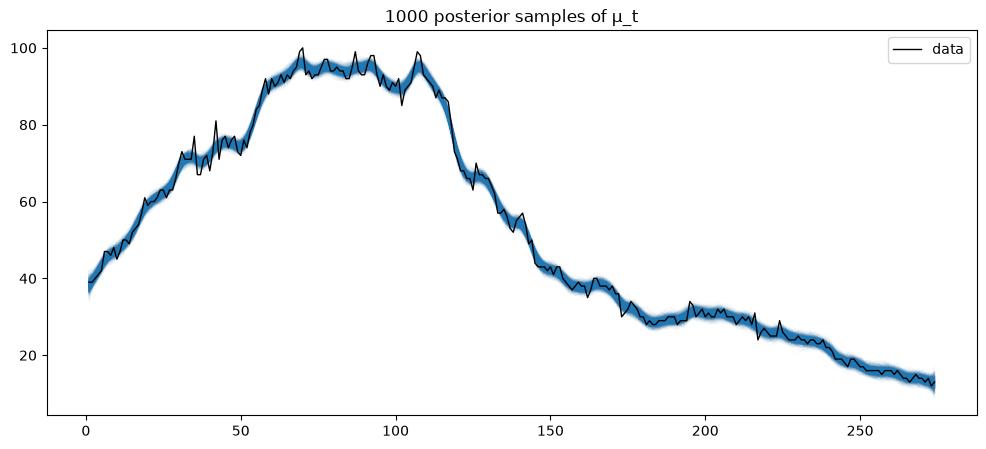

In [6]:
from scipy.linalg import cho_factor, cho_solve, solve_triangular

rng = np.random.default_rng(0)
Nsamp = 1000

# 1. sample (tau, sigma) from the grid posterior
P = np.exp(LP - LP.max())
P /= P.sum()
flat = rng.choice(P.size, size=Nsamp, p=P.ravel())
ti, si = np.unravel_index(flat, P.shape)

# 2. for each (tau, sigma), sample beta ~ N(M^-1 X'y / sigma^2, M^-1)
mu_samples = np.empty((Nsamp, n))
for s in range(Nsamp):
    tau, sigma = taus[ti[s]], sigmas[si[s]]
    M = XtX / sigma**2 + D / tau**2
    c, low = cho_factor(M, lower=True)               # M = L L^T
    mean = cho_solve((c, low), Xty / sigma**2)
    z = rng.standard_normal(n)
    beta = mean + solve_triangular(c, z, lower=True, trans='T')  # cov = M^-1
    mu_samples[s] = X @ beta

# 3. plot
plt.figure(figsize=(12, 5))
plt.plot(t, y, color='black', lw=1, label='data', zorder=3)
for s in range(Nsamp):
    plt.plot(t, mu_samples[s], color='C0', alpha=0.02, lw=1)
plt.title('1000 posterior samples of μ_t')
plt.legend()
plt.show()

I would say the uncertaity in this plot make sense as it follows or encapsulate many of the mini peaks and jumps we see over the time series data. This make sense if we imagine a centered trend with noise around it that is the jumps, our uncertainty would then be porpotional to that noise or "jumps".

iii

roughness  ridge (CV): 108.9
roughness  Bayes mean: 20.56


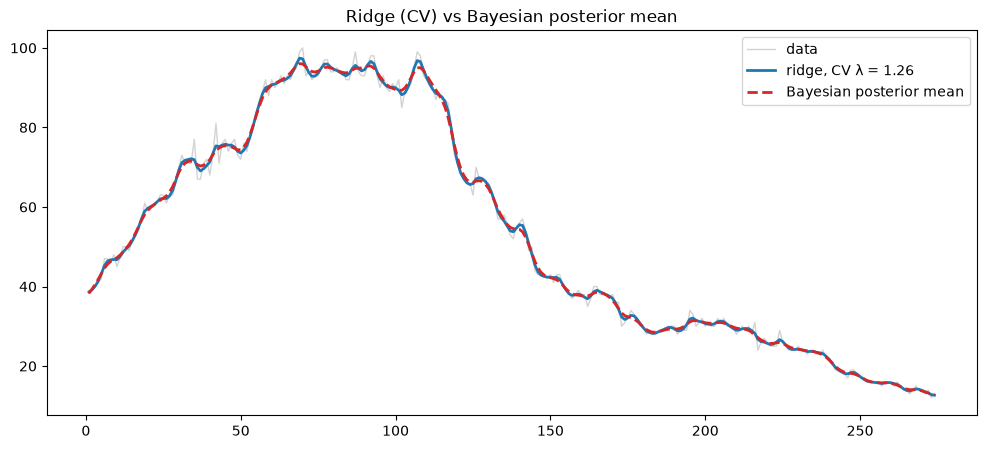

In [7]:
mu_bayes = mu_samples.mean(axis=0)

# smoothness: sum of squared second differences (smaller = smoother)
rough = lambda m: np.sum(np.diff(m, 2)**2)
print(f"roughness  ridge (CV): {rough(mu_best):.4g}")
print(f"roughness  Bayes mean: {rough(mu_bayes):.4g}")

plt.figure(figsize=(12, 5))
plt.plot(t, y, color='lightgray', lw=1, label='data')
plt.plot(t, mu_best, color='C0', lw=2, label=f'ridge, CV λ = {best_lam:.3g}')
plt.plot(t, mu_bayes, color='C3', lw=2, ls='--', label='Bayesian posterior mean')
plt.title('Ridge (CV) vs Bayesian posterior mean')
plt.legend()
plt.show()

I think these fits are prety similar however there are a few cases where the ridge is able to model the spikes a little better then the bayesian posterier mean. We see this in a few spots where the blue line is able to follow the general trend but jumps a little higher/lower compared to the mean posterier.